# Shallow water on the sphere: families, forcings, diagnostics and coarse-graining

`SphericalShallowWater` solves the shallow water equations on the rotating sphere with spherical harmonics. This notebook runs every initial-condition family and every forcing at a small size, and shows the diagnostics, the coarse-grained truth and the ERA5 states. The `era5` family reads the WeatherBench2 copy of ERA5: it needs the `era5` extra (`pip install "autosim[spherical,era5]"`) and network access.

Everything runs at the band limit `lmax = 43` on a 64 x 128 Gauss-Legendre grid (about 2.8 degrees), in about fifteen minutes on one GPU. The relaxation, drag and forcing values are those of the benchmark datasets, which are the configs `shallow_water_sphere_ds1_*.yaml` to `shallow_water_sphere_ds6_*.yaml`.

The saved channels are `h` (height of the free surface above the mean depth, in m), `u_phi` (eastward wind) and `u_theta` (southward wind), both in m/s.

The maps are drawn on the sphere with `plot_sphere` of torch-harmonics, which needs cartopy (`pip install cartopy`). Every map shows the hemisphere centred on 50°N, 270°E.

In [1]:
import math
import os

import matplotlib.pyplot as plt
import torch
from torch_harmonics.plotting import plot_sphere

from autosim.era5 import era5_hours, load_era5_climatology, load_era5_fields
from autosim.experimental.simulations.shallow_water_sphere import (
    DampingSettings,
    Era5Settings,
    LocalBackscatterSettings,
    PeriodicForcingSettings,
    SkebsSettings,
    SphericalShallowWater,
    SpptSettings,
    era5_initial_condition,
    era5_source_dynamics,
    fields_to_spectral,
    height_error_norms,
    height_power_spectrum,
    invariants,
    kinetic_energy_spectrum,
    non_zonal_energy,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("figures", exist_ok=True)

lmax = 43
nlat = 64
nlon = 128
radius = 6.37122e6  # [m]
gravity = 9.80616  # [m/s2]
w92_case7_hours = era5_hours("1978-12-21T00")  # first state of W92 case 7

# Every map is drawn on the sphere, seen from above this point
view_latitude = 50.0  # [deg]
view_longitude = 270.0  # [deg]

## Initial-condition families

`initial_condition` selects the family, and `parameters_range` gives the bounds of its parameters. Equal bounds fix a parameter, so the ranges below give the published case of each family:

- `galewsky`: unstable jet with a height bump (Galewsky et al. 2004);
- `mountain`: zonal flow over a Gaussian mountain (W92 case 5, with the mountain of DCMIP-2008);
- `era5`: the ERA5 state at 500 hPa of 1978-12-21T00, over the Earth's orography, after a balance step (W92 case 7).

Each run lasts 6 days and is saved every 24 h.

In [2]:
simulators = {}

simulators["galewsky"] = SphericalShallowWater(
    lmax=lmax, nlat=nlat, nlon=nlon,
    T=144.0, dt_save=24.0, skip_nt=0,
    batch_size=1, device=device, log_level="warning",
    initial_condition="galewsky",
    mean_depth=1.0e4,
    parameters_range={
        "jet_speed": (80.0, 80.0),
        "height_perturbation_m": (120.0, 120.0),
        "perturbation_lon": (math.pi, math.pi),
        "perturbation_lat": (math.pi / 4, math.pi / 4),
    },
)

simulators["mountain"] = SphericalShallowWater(
    lmax=lmax, nlat=nlat, nlon=nlon,
    T=144.0, dt_save=24.0, skip_nt=0,
    batch_size=1, device=device, log_level="warning",
    initial_condition="mountain",
    mean_depth=5960.0,
    parameters_range={
        "flow_speed": (20.0, 20.0),
        "mountain_height": (2000.0, 2000.0),
        "mountain_width": (1.5e6 / radius, 1.5e6 / radius),  # 1500 km
        "mountain_lon": (1.5 * math.pi, 1.5 * math.pi),
        "mountain_lat": (math.pi / 6, math.pi / 6),
    },
    return_constant_fields=True,
)

simulators["era5"] = SphericalShallowWater(
    lmax=lmax, nlat=nlat, nlon=nlon,
    T=144.0, dt_save=24.0, skip_nt=0,
    batch_size=1, device=device, log_level="warning",
    initial_condition="era5",
    mean_depth=6000.0,
    era5=Era5Settings(orography_exponent=15 / 16, orography_shift=True),
    parameters_range={"era5_time": (w92_case7_hours, w92_case7_hours)},
    return_constant_fields=True,
)

family_runs = {}
for family in simulators:
    family_runs[family] = simulators[family].forward_samples_spatiotemporal(n=1, random_seed=0)
    print(family, tuple(family_runs[family]["data"].shape))

galewsky (1, 7, 64, 128, 3)


mountain (1, 7, 64, 128, 3)


era5 (1, 7, 64, 128, 3)


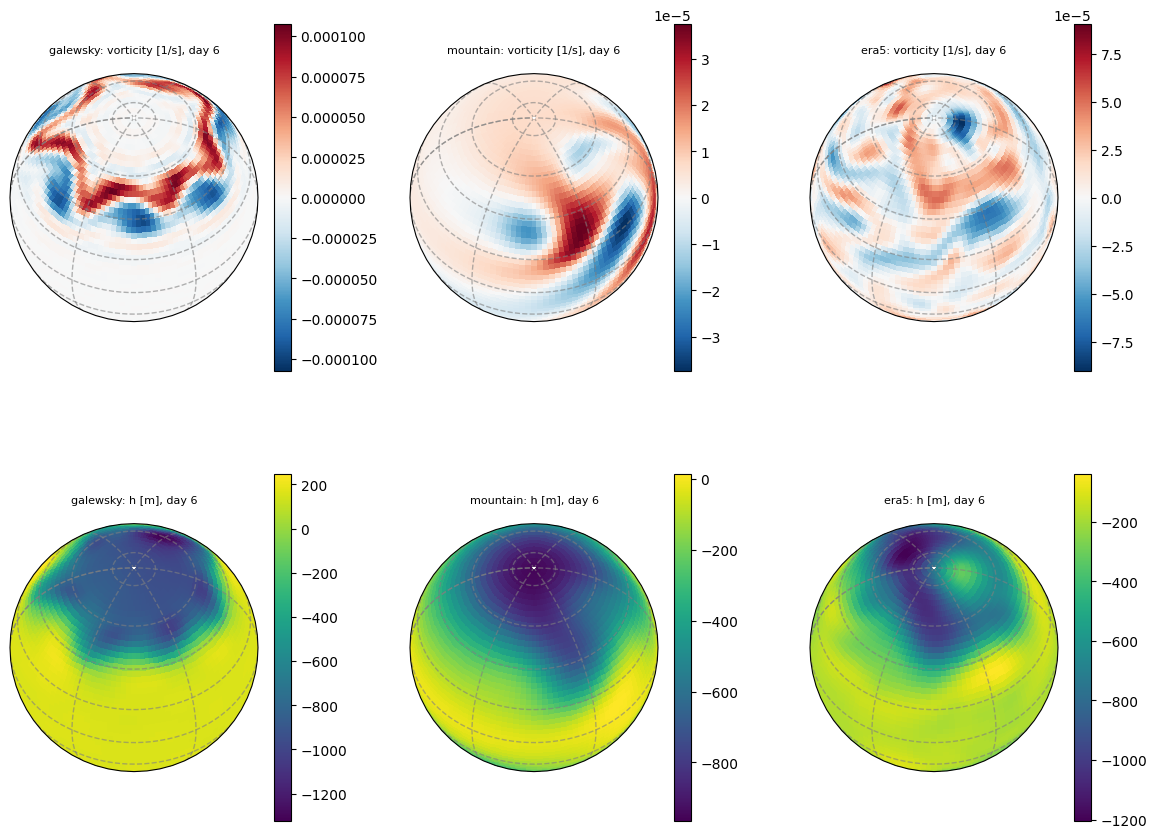

In [3]:
fig = plt.figure(figsize=(12, 9))
panels = fig.subfigures(2, 3)
for column, family in enumerate(simulators):
    sim = simulators[family]
    last_frame = family_runs[family]["data"][:, -1]
    state = fields_to_spectral(sim.dynamics, last_frame)
    vorticity = sim.dynamics.to_grid(state[:, 1])[0].cpu()
    height = last_frame[0, :, :, 0]

    limit = vorticity.abs().max().item()
    plot_sphere(
        vorticity, fig=panels[0, column], grid=sim.grid,
        projection="orthographic", central_latitude=view_latitude, central_longitude=view_longitude,
        cmap="RdBu_r", vmin=-limit, vmax=limit, colorbar=True, gridlines=True,
        title=family + ": vorticity [1/s], day 6",
    )
    plot_sphere(
        height, fig=panels[1, column], grid=sim.grid,
        projection="orthographic", central_latitude=view_latitude, central_longitude=view_longitude,
        cmap="viridis", colorbar=True, gridlines=True,
        title=family + ": h [m], day 6",
    )
fig.savefig("figures/benchmark_families.png", dpi=110, bbox_inches="tight")
plt.show()

## Spectra

`fields_to_spectral` converts saved frames back to spherical-harmonic coefficients. `height_power_spectrum` gives the power of the depth per degree $l$. `kinetic_energy_spectrum` gives the kinetic energy per degree, split into a rotational part (from the vorticity) and a divergent part (from the divergence). Their sum over the degrees is the global mean of $\tfrac12|\mathbf{u}|^2$.

In [4]:
height_spectra = {}
rotational_spectra = {}
divergent_spectra = {}
for family in simulators:
    sim = simulators[family]
    last_frame = family_runs[family]["data"][:, -1]
    state = fields_to_spectral(sim.dynamics, last_frame)

    height_spectrum = height_power_spectrum(state, gravity)  # (1, lmax)
    kinetic_spectrum = kinetic_energy_spectrum(state, radius)  # (1, 2, lmax): rotational, divergent
    height_spectra[family] = height_spectrum[0].cpu()
    rotational_spectra[family] = kinetic_spectrum[0, 0].cpu()
    divergent_spectra[family] = kinetic_spectrum[0, 1].cpu()

    rotational_energy = rotational_spectra[family].sum().item()
    divergent_energy = divergent_spectra[family].sum().item()
    mean_kinetic_energy = rotational_energy + divergent_energy
    divergent_share = divergent_energy / mean_kinetic_energy
    print(f"{family:22s} mean kinetic energy {mean_kinetic_energy:8.2f} m2/s2, divergent share {divergent_share:.1e}")

galewsky               mean kinetic energy   150.55 m2/s2, divergent share 9.5e-05
mountain               mean kinetic energy   138.21 m2/s2, divergent share 8.6e-04
era5                   mean kinetic energy   125.38 m2/s2, divergent share 3.2e-03


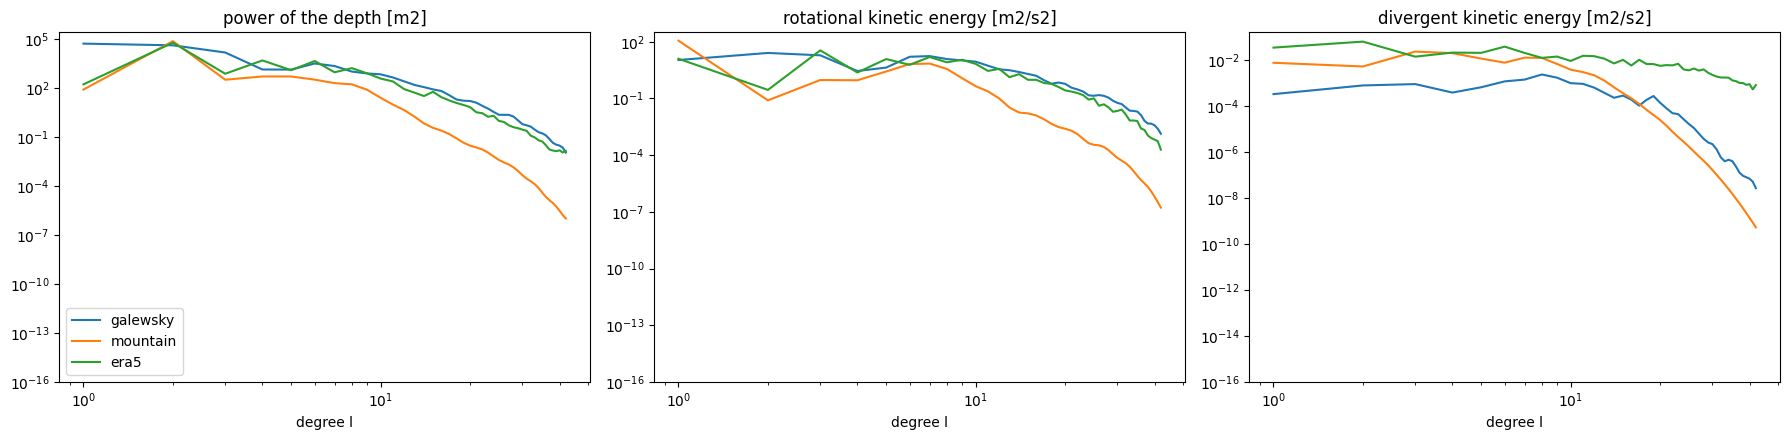

In [5]:
degrees = torch.arange(lmax)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for family in simulators:
    axes[0].loglog(degrees[1:], height_spectra[family][1:], label=family)
    axes[1].loglog(degrees[1:], rotational_spectra[family][1:], label=family)
    axes[2].loglog(degrees[1:], divergent_spectra[family][1:].clamp(min=1e-30), label=family)
axes[0].set_title("power of the depth [m2]")
axes[1].set_title("rotational kinetic energy [m2/s2]")
axes[2].set_title("divergent kinetic energy [m2/s2]")
for axis in axes:
    axis.set_xlabel("degree l")
    axis.set_ylim(bottom=1e-16)
axes[0].legend()
fig.tight_layout()
fig.savefig("figures/benchmark_spectra.png", dpi=110)
plt.show()

## Invariants

`invariants` integrates the mass, the total energy and the potential enstrophy over the sphere. Without forcing, the hyperdiffusion is the only sink, so the mass is constant and the two others decrease slowly. W92 normalises each invariant as $(I(t) - I(0)) / I(0)$.

In [6]:
# Invariants along the Galewsky run, from its saved frames
sim = simulators["galewsky"]
frames = family_runs["galewsky"]["data"][0]
invariant_series = []
for frame in range(frames.shape[0]):
    state = fields_to_spectral(sim.dynamics, frames[frame : frame + 1])
    invariant_series.append(invariants(sim.dynamics, state)[0].cpu())
invariant_series = torch.stack(invariant_series)
relative_change = (invariant_series - invariant_series[0]) / invariant_series[0]
mass_drift = relative_change[-1, 0].item()
energy_drift = relative_change[-1, 1].item()
enstrophy_drift = relative_change[-1, 2].item()
print(f"relative change at day 6: mass {mass_drift:.1e}, energy {energy_drift:.1e}, potential enstrophy {enstrophy_drift:.1e}")

relative change at day 6: mass 5.5e-12, energy -1.3e-04, potential enstrophy -2.5e-02


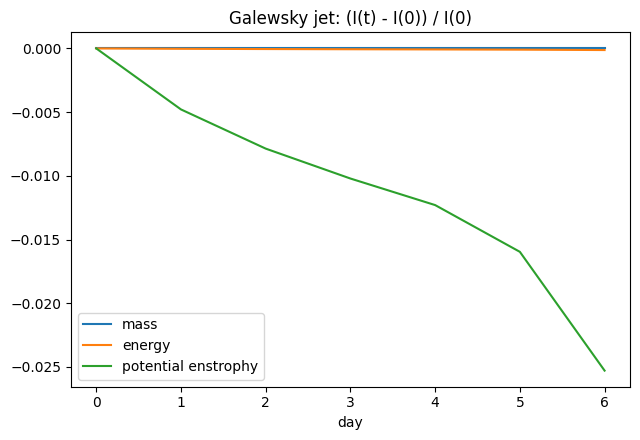

In [7]:
fig, axis = plt.subplots(figsize=(6.5, 4.5))
days = torch.arange(relative_change.shape[0])
axis.plot(days, relative_change[:, 0], label="mass")
axis.plot(days, relative_change[:, 1], label="energy")
axis.plot(days, relative_change[:, 2], label="potential enstrophy")
axis.set_xlabel("day")
axis.set_title("Galewsky jet: (I(t) - I(0)) / I(0)")
axis.legend()
fig.tight_layout()
fig.savefig("figures/benchmark_invariants.png", dpi=110)
plt.show()

## Forced-dissipative regime

With `damping=DampingSettings(relaxation_time=..., drag_time=...)` the height relaxes towards the balanced height of a zonal jet, and the wind is damped. The jet that the relaxation rebuilds is unstable, so eddies keep forming and the flow reaches a statistically steady state. Both times are in hours. The eddies persist only with a fast relaxation and a slow drag: 1 day and 100 days here, the values of the datasets 1 to 3 and 5.

`return_energy_budget=True` returns the energy at every saved frame and the energy change of each process between frames. The run starts from the Galewsky jet and lasts 60 days.

In [8]:
RELAXATION_HOURS = 24.0
DRAG_HOURS = 2400.0

spinup = SphericalShallowWater(
    lmax=lmax, nlat=nlat, nlon=nlon,
    T=60 * 24.0, dt_save=12.0, skip_nt=0,
    batch_size=1, device=device, log_level="warning",
    initial_condition="galewsky",
    parameters_range={
        "jet_speed": (80.0, 80.0),
        "height_perturbation_m": (120.0, 120.0),
        "perturbation_lon": (math.pi, math.pi),
        "perturbation_lat": (math.pi / 4, math.pi / 4),
    },
    damping=DampingSettings(
        relaxation_time=RELAXATION_HOURS, relaxation_jet_speed=80.0, drag_time=DRAG_HOURS
    ),
    return_energy_budget=True,
)
spinup_run = spinup.forward_samples_spatiotemporal(n=1, random_seed=0)
spinup_frames = spinup_run["data"][0]
spinup_budget = spinup_run["energy_budget"][0]
print("columns of the energy budget:", spinup.energy_budget_names)

eddy_energy = []
for frame in range(spinup_frames.shape[0]):
    state = fields_to_spectral(spinup.dynamics, spinup_frames[frame : frame + 1])
    eddy_energy.append(non_zonal_energy(state, radius, gravity, 1.0e4).item())

state = fields_to_spectral(spinup.dynamics, spinup_frames[-1:])
spun_up_vorticity = spinup.dynamics.to_grid(state[:, 1])[0].cpu()

columns of the energy budget: ['total_energy', 'deterministic_energy_change', 'hyperviscous_energy_change', 'drag_energy_change', 'relaxation_energy_change', 'forcing_energy_change', 'sppt_energy_change', 'periodic_energy_change', 'effective_forcing_energy_rate']


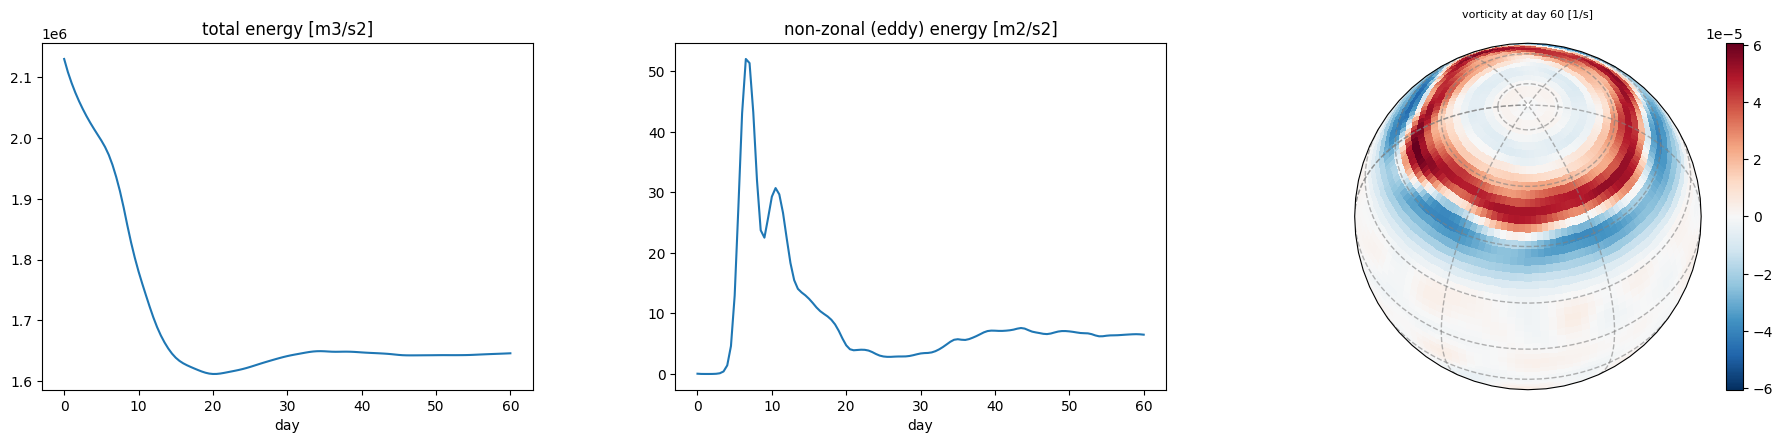

In [9]:
spinup_days = torch.arange(spinup_frames.shape[0]) * 0.5
fig = plt.figure(figsize=(19, 4.5))
panels = fig.subfigures(1, 3)

axis = panels[0].subplots()
axis.plot(spinup_days, spinup_budget[:, 0])
axis.set_xlabel("day")
axis.set_title("total energy [m3/s2]")

axis = panels[1].subplots()
axis.plot(spinup_days, eddy_energy)
axis.set_xlabel("day")
axis.set_title("non-zonal (eddy) energy [m2/s2]")

limit = spun_up_vorticity.abs().max().item()
plot_sphere(
    spun_up_vorticity, fig=panels[2], grid=spinup.grid,
    projection="orthographic", central_latitude=view_latitude, central_longitude=view_longitude,
    cmap="RdBu_r", vmin=-limit, vmax=limit, colorbar=True, gridlines=True,
    title="vorticity at day 60 [1/s]",
)
fig.savefig("figures/benchmark_spinup.png", dpi=110, bbox_inches="tight")
plt.show()

## Forcings

Each forcing is one argument of the simulator, a settings dataclass, and they can be added to the relaxed jet alone or together:

- `skebs=SkebsSettings(...)`: stochastic kinetic-energy backscatter, a streamfunction pattern in spherical harmonics, each coefficient an AR(1) process with the decorrelation time `correlation_time` (Berner et al. 2009). `energy_rate` is the kinetic energy that it injects per unit mass and time, and `degree_min` and `degree_max` restrict it to a band of degrees.
- `global_backscatter=GlobalBackscatterSettings(fraction)` and `local_backscatter=LocalBackscatterSettings(fraction)` add a fraction of the diagnosed dissipation to the SKEBS energy rate. With the local one the forcing is stronger where the flow dissipates more, so the noise depends on the state. `include_drag=True` counts the loss to the drag as dissipation, next to the loss to the hyperdiffusion. The two can be combined.
- `sppt=SpptSettings(...)`: stochastically perturbed physics tendencies (Buizza et al. 1999; Palmer et al. 2009; Leutbecher et al. 2017). The increment of the relaxation and the drag is multiplied by $1 + r$, with $r$ the sum of three AR(1) Gaussian fields of 500, 1000 and 2000 km, clipped to $[-1, 1]$. SKEBS is additive and acts on the wind; SPPT is multiplicative and acts mostly on the height.
- `periodic=PeriodicForcingSettings()`: the daily and yearly height source of The Well's PlanetSWE, a deterministic forcing that makes the run depend on the time.

Each run below spins up for 60 days with its own forcing and saves the next 48 h every 6 h. `return_additional_input_fields=True` returns the increments that the forcings added between saved frames. The energy rate printed below is that of the SKEBS pattern.

In [10]:
FORCING_ENERGY_RATE = 1.0e-5
FORCING_CORRELATION_HOURS = 6.0
SPINUP_HOURS = 60 * 24.0
GALEWSKY_JET = {
    "jet_speed": (80.0, 80.0),
    "height_perturbation_m": (120.0, 120.0),
    "perturbation_lon": (math.pi, math.pi),
    "perturbation_lat": (math.pi / 4, math.pi / 4),
}

forcing_options = {
    "none": {},
    "skebs": {
        "skebs": SkebsSettings(
            energy_rate=FORCING_ENERGY_RATE, correlation_time=FORCING_CORRELATION_HOURS
        ),
    },
    "local backscatter": {
        "skebs": SkebsSettings(energy_rate=0.0, correlation_time=FORCING_CORRELATION_HOURS),
        "local_backscatter": LocalBackscatterSettings(fraction=0.2, include_drag=True),
    },
    "sppt": {
        "sppt": SpptSettings(
            amplitudes=[0.52, 0.18, 0.06],
            length_scales=[500.0e3, 1000.0e3, 2000.0e3],
            correlation_times=[6.0, 72.0, 720.0],
        ),
    },
    "periodic": {"periodic": PeriodicForcingSettings(amplitude=2.0)},
}

forced_simulators = {}
for name, options in forcing_options.items():
    forced_simulators[name] = SphericalShallowWater(
        lmax=lmax, nlat=nlat, nlon=nlon,
        T=SPINUP_HOURS + 48.0, dt_save=6.0, skip_nt=round(SPINUP_HOURS / 6.0),
        batch_size=1, device=device, log_level="warning",
        initial_condition="galewsky", parameters_range=GALEWSKY_JET,
        damping=DampingSettings(relaxation_time=RELAXATION_HOURS, drag_time=DRAG_HOURS),
        return_additional_input_fields=True, return_energy_budget=True,
        **options,
    )

forced_runs = {}
names = forced_simulators["none"].energy_budget_names
work_columns = [names.index(column) for column in ("forcing_energy_change", "sppt_energy_change", "periodic_energy_change")]
rate_column = names.index("effective_forcing_energy_rate")
for name in forced_simulators:
    forced_runs[name] = forced_simulators[name].forward_samples_spatiotemporal(n=1, random_seed=1)
    budget = forced_runs[name]["energy_budget"][0]  # (frames, columns of energy_budget_names)
    work = budget[:-1, work_columns].sum(dim=0)
    mean_energy_rate = budget[:-1, rate_column].mean().item()
    print(
        f"{name:18s} work over 48 h [m3/s2]: kinetic {work[0].item():9.1f}, sppt {work[1].item():9.1f}, "
        f"periodic {work[2].item():9.1f}; kinetic energy rate {mean_energy_rate:.2e} m2/s3"
    )

none               work over 48 h [m3/s2]: kinetic       0.0, sppt       0.0, periodic       0.0; kinetic energy rate 0.00e+00 m2/s3


skebs              work over 48 h [m3/s2]: kinetic   10251.9, sppt       0.0, periodic       0.0; kinetic energy rate 1.00e-05 m2/s3


local backscatter  work over 48 h [m3/s2]: kinetic    3361.7, sppt       0.0, periodic       0.0; kinetic energy rate 5.69e-06 m2/s3


sppt               work over 48 h [m3/s2]: kinetic       0.0, sppt   -7752.1, periodic       0.0; kinetic energy rate 0.00e+00 m2/s3


periodic           work over 48 h [m3/s2]: kinetic       0.0, sppt       0.0, periodic    2386.6; kinetic energy rate 0.00e+00 m2/s3


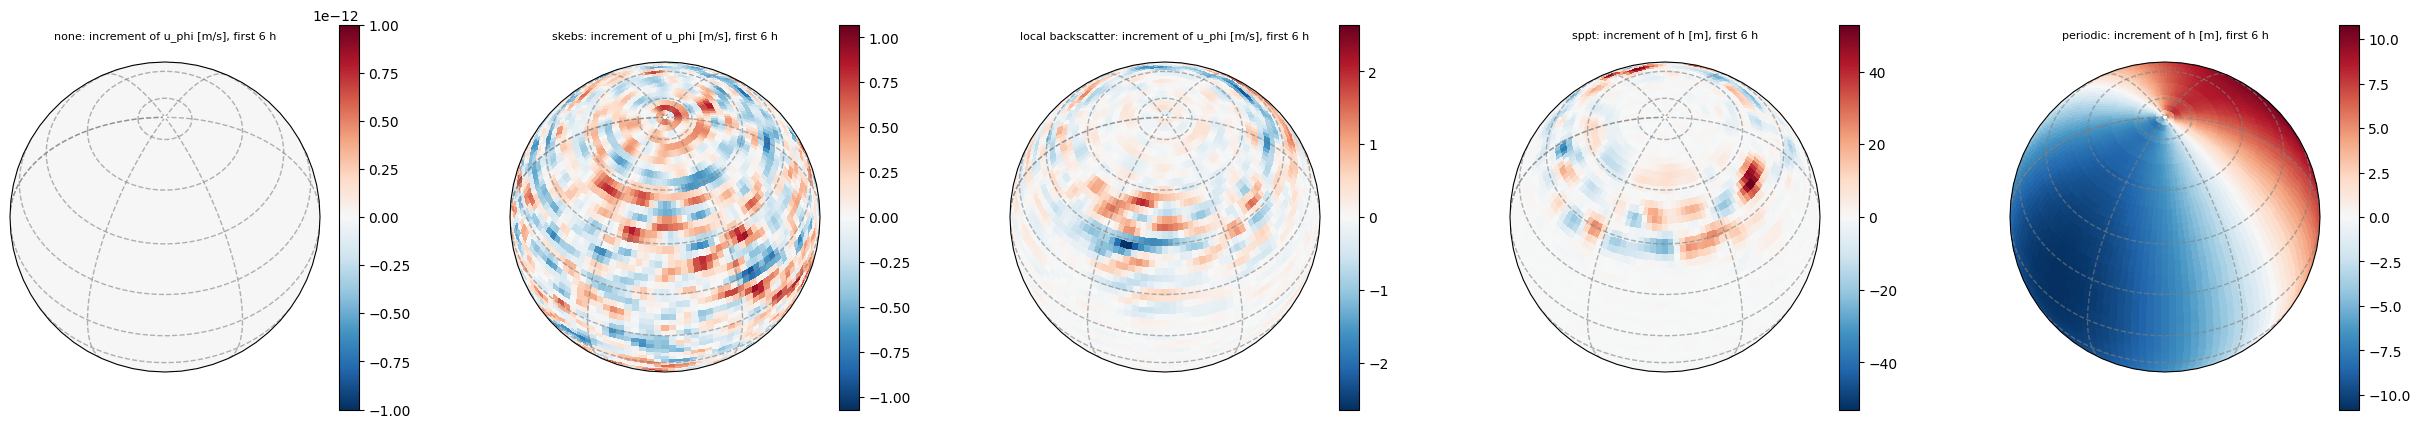

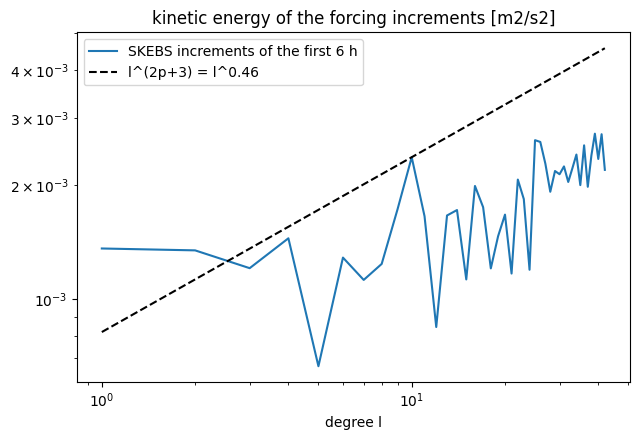

In [11]:
fig = plt.figure(figsize=(25, 5))
panels = fig.subfigures(1, 5)
for column, name in enumerate(forced_simulators):
    # SPPT and the periodic forcing act mostly on the height, the others on the wind
    channel, label = (0, "h [m]") if name in ("sppt", "periodic") else (1, "u_phi [m/s]")
    increments = forced_runs[name]["additional_input_fields"][0, 0, :, :, channel]
    limit = max(increments.abs().max().item(), 1e-12)
    plot_sphere(
        increments, fig=panels[column], grid=forced_simulators[name].grid,
        projection="orthographic", central_latitude=view_latitude, central_longitude=view_longitude,
        cmap="RdBu_r", vmin=-limit, vmax=limit, colorbar=True, gridlines=True,
        title=name + ": increment of " + label + ", first 6 h",
    )
fig.savefig("figures/benchmark_forcing_increments.png", dpi=110, bbox_inches="tight")
plt.show()

# Kinetic-energy spectrum of the SKEBS increments, against the power law l^(2p+3)
sim = forced_simulators["skebs"]
increments = forced_runs["skebs"]["additional_input_fields"][:, 0]
state = fields_to_spectral(sim.dynamics, increments)
increment_spectrum = kinetic_energy_spectrum(state, radius)[0, 0].cpu()
slope = 2 * sim.skebs.spectral_slope + 3
reference = increment_spectrum[10] * (degrees[1:] / 10.0) ** slope
fig, axis = plt.subplots(figsize=(6.5, 4.5))
axis.loglog(degrees[1:], increment_spectrum[1:], label="SKEBS increments of the first 6 h")
axis.loglog(degrees[1:], reference, "k--", label=f"l^(2p+3) = l^{slope:.2f}")
axis.set_xlabel("degree l")
axis.set_title("kinetic energy of the forcing increments [m2/s2]")
axis.legend()
fig.tight_layout()
fig.savefig("figures/benchmark_forcing_spectrum.png", dpi=110)
plt.show()

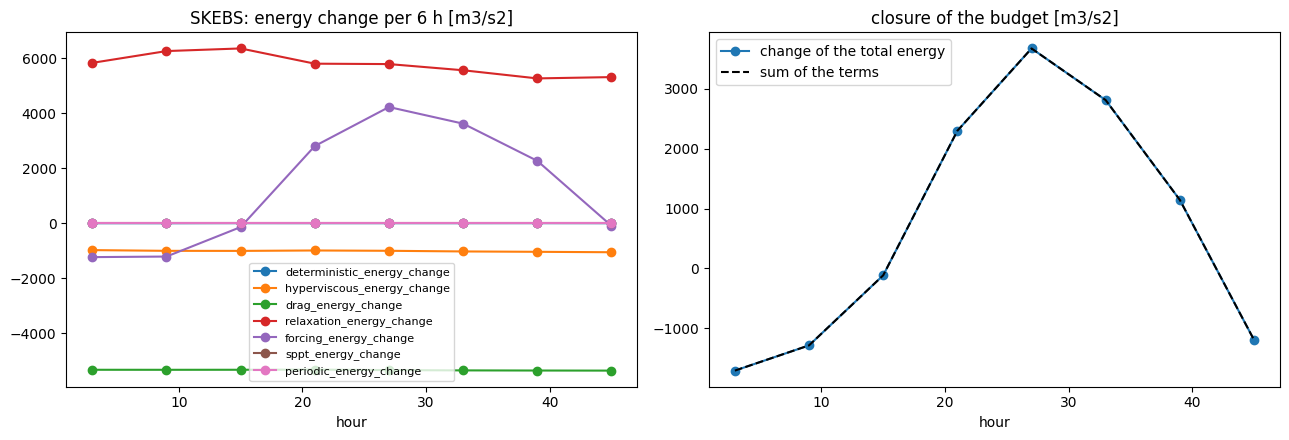

In [12]:
budget = forced_runs["skebs"]["energy_budget"][0]
interval_hours = torch.arange(budget.shape[0] - 1) * 6.0 + 3.0
energy_change = budget[1:, 0] - budget[:-1, 0]
sum_of_terms = budget[:-1, 1:rate_column].sum(dim=1)  # the energy changes of the processes

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for column in range(1, rate_column):
    axes[0].plot(interval_hours, budget[:-1, column], "o-", label=names[column])
axes[0].set_xlabel("hour")
axes[0].set_title("SKEBS: energy change per 6 h [m3/s2]")
axes[0].legend(fontsize=8)
axes[1].plot(interval_hours, energy_change, "o-", label="change of the total energy")
axes[1].plot(interval_hours, sum_of_terms, "k--", label="sum of the terms")
axes[1].set_xlabel("hour")
axes[1].set_title("closure of the budget [m3/s2]")
axes[1].legend()
fig.tight_layout()
fig.savefig("figures/benchmark_energy_budget.png", dpi=110)
plt.show()

## Coarse-grained truth and physics baseline

`output_lmax` saves the run truncated to a lower band limit, on a coarser grid: the truth as an emulator at that resolution sees it. Here the solver runs at `lmax = 86` and saves at `lmax = 43`. `return_baseline=True` also runs the solver at `lmax = 43` from the truncated first frame. The difference between the two comes from the scales that the low resolution does not resolve, without any added noise.

In [15]:
coarse_simulator = SphericalShallowWater(
    lmax=86, nlat=128, nlon=256,
    T=144.0, dt_save=12.0, skip_nt=0,
    batch_size=1, device=device, log_level="warning",
    initial_condition="galewsky",
    parameters_range={
        "jet_speed": (80.0, 80.0),
        "height_perturbation_m": (120.0, 120.0),
        "perturbation_lon": (math.pi, math.pi),
        "perturbation_lat": (math.pi / 4, math.pi / 4),
    },
    output_lmax=43, output_nlat=64, output_nlon=128,
    return_baseline=True,
)
coarse_run = coarse_simulator.forward_samples_spatiotemporal(n=1, random_seed=0)
coarse_truth = coarse_run["data"][0]
baseline = coarse_run["baseline"][0]
print("coarse-grained truth:", tuple(coarse_truth.shape), "baseline:", tuple(baseline.shape))

low = coarse_simulator.output_dynamics
baseline_errors = []
for frame in range(coarse_truth.shape[0]):
    height_truth = coarse_truth[frame, :, :, 0].double().to(device) + 1.0e4
    height_baseline = baseline[frame, :, :, 0].double().to(device) + 1.0e4
    l1, l2, linf = height_error_norms(height_baseline, height_truth, low.quad_weights)
    baseline_errors.append(l2.item())

state = fields_to_spectral(low, coarse_truth[-1:])
vorticity_truth = low.to_grid(state[:, 1])[0].cpu()
state = fields_to_spectral(low, baseline[-1:])
vorticity_baseline = low.to_grid(state[:, 1])[0].cpu()

coarse-grained truth: (13, 64, 128, 3) baseline: (13, 64, 128, 3)


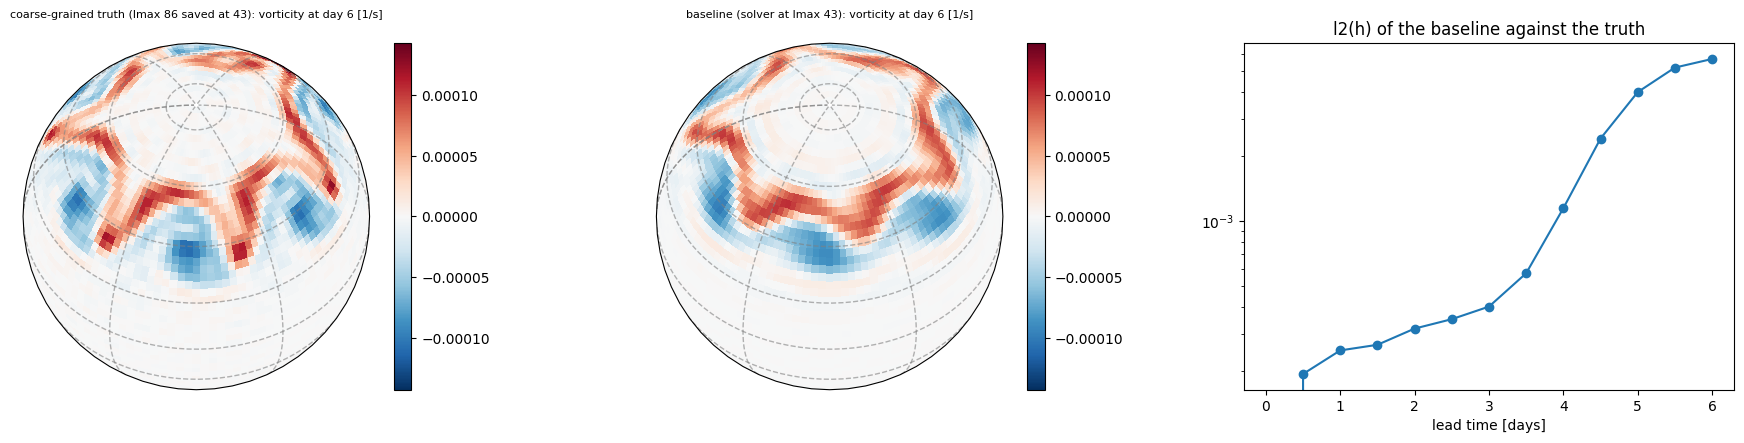

In [16]:
fig = plt.figure(figsize=(19, 4.5))
panels = fig.subfigures(1, 3)

limit = vorticity_truth.abs().max().item()
plot_sphere(
    vorticity_truth, fig=panels[0], grid=coarse_simulator.output_grid,
    projection="orthographic", central_latitude=view_latitude, central_longitude=view_longitude,
    cmap="RdBu_r", vmin=-limit, vmax=limit, colorbar=True, gridlines=True,
    title="coarse-grained truth (lmax 86 saved at 43): vorticity at day 6 [1/s]",
)
plot_sphere(
    vorticity_baseline, fig=panels[1], grid=coarse_simulator.output_grid,
    projection="orthographic", central_latitude=view_latitude, central_longitude=view_longitude,
    cmap="RdBu_r", vmin=-limit, vmax=limit, colorbar=True, gridlines=True,
    title="baseline (solver at lmax 43): vorticity at day 6 [1/s]",
)

axis = panels[2].subplots()
axis.semilogy(torch.arange(len(baseline_errors)) * 0.5, baseline_errors, "o-")
axis.set_xlabel("lead time [days]")
axis.set_title("l2(h) of the baseline against the truth")
fig.savefig("figures/benchmark_coarse_graining.png", dpi=110, bbox_inches="tight")
plt.show()

## ERA5 states (W92 case 7)

The `era5` family reads the geopotential and the wind at 500 hPa, and the surface geopotential, from the WeatherBench2 copy of ERA5. The fields are analysed on their 0.25 degree grid, truncated to the band limit, and balanced: the divergence is removed and the height is replaced by the one in nonlinear balance with the wind, with the same global mean. W92 asks for the changes made by such an initialisation; the map below shows them for the first state of case 7.

The fluid depth is the 500 hPa height minus the orography, so it is smallest over Tibet, the Karakoram and the Antarctic plateau. The truncated orography of Tibet reaches 5.65 km at `lmax = 86`, close to the 500 hPa surface, so the datasets compress the orography as The Well's PlanetSWE: $\operatorname{sign}(h_s)|h_s|^{15/16}$, shifted to a minimum of 0 (`Era5Settings(orography_exponent, orography_shift)`), which brings Tibet to about 3.4 km. The maximum depth sets `mean_depth` of datasets 5 and 6, which gives the gravity-wave speed of the time step. The table covers the three dates of W92 case 7 and three later ones, at `lmax = 86`. Dataset 5 relaxes the height towards the ERA5 1990-2019 climatology of the start date's day and hour; the cell also prints how far the first state of case 7 lies from that target.

In [ ]:
era5_dates = ["1978-12-21T00", "1979-01-09T00", "1979-01-16T00", "1990-01-01T06", "2010-07-15T12", "2022-08-01T18"]
era5_fields = load_era5_fields(torch.tensor([era5_hours(date) for date in era5_dates]))

dataset_simulator = SphericalShallowWater(
    lmax=86, nlat=128, nlon=256, T=0.0, dt_save=6.0, skip_nt=0,
    device=device, log_level="warning",
    initial_condition="era5", mean_depth=6000.0,
    era5=Era5Settings(orography_exponent=15 / 16, orography_shift=True),
)
dataset_dynamics = dataset_simulator.dynamics
era5_source = era5_source_dynamics(dataset_dynamics, era5_fields)
era5_state, era5_surface = era5_initial_condition(dataset_dynamics, era5_source, era5_fields, 15 / 16, True)
fluid_depth = dataset_dynamics.to_grid(era5_state[:, 0]) / gravity
for index, date in enumerate(era5_dates):
    print(
        f"{date}: fluid depth from {fluid_depth[index].min().item():7.1f} to {fluid_depth[index].max().item():7.1f} m, "
        f"z500 / g up to {(era5_fields.geopotential[index].max() / gravity).item():7.1f} m"
    )

# Change of the height made by the balance step, for the first date, at lmax = 43
case7_dynamics = simulators["era5"].dynamics
case7_source = era5_source_dynamics(case7_dynamics, era5_fields)
balanced_state, case7_surface = era5_initial_condition(case7_dynamics, case7_source, era5_fields, 15 / 16, True)
analysed_free_surface = case7_source.to_coefficients(era5_fields.geopotential.to(device))
balanced_free_surface = balanced_state[:, 0] + case7_surface
balance_change = case7_dynamics.to_grid(balanced_free_surface - analysed_free_surface)[0].cpu() / gravity
orography = case7_dynamics.to_grid(case7_surface)[0].cpu() / gravity
print(f"largest change of the height by the balance step: {balance_change.abs().max().item():.1f} m")

# Relaxation target of dataset 5: the climatological 500 hPa height of the same day and hour
climatology = load_era5_climatology(torch.tensor([w92_case7_hours]))
target_height = case7_dynamics.to_grid(case7_source.to_coefficients(climatology.to(device)))[0].cpu() / gravity
analysed_height = case7_dynamics.to_grid(analysed_free_surface[:1])[0].cpu() / gravity
weights = case7_dynamics.quad_weights.cpu()
rms = torch.sqrt(((analysed_height - target_height) ** 2 * weights).sum() / weights.sum()).item()
print(f"1978-12-21T00: root-mean-square distance between the analysed height and the climatology: {rms:.1f} m")

1978-12-21T00: fluid depth from  2329.8 to  6032.7 m, z500 / g up to  5903.7 m
1979-01-09T00: fluid depth from  2287.4 to  6036.5 m, z500 / g up to  5915.6 m
1979-01-16T00: fluid depth from  2214.3 to  6035.9 m, z500 / g up to  5917.2 m
1990-01-01T06: fluid depth from  2203.9 to  5994.3 m, z500 / g up to  5927.6 m
2010-07-15T12: fluid depth from  2398.3 to  6018.4 m, z500 / g up to  5963.4 m
2022-08-01T18: fluid depth from  2393.0 to  6047.2 m, z500 / g up to  6018.6 m
largest change of the height by the balance step: 35.2 m


1978-12-21T00: root-mean-square distance between the analysed height and the climatology: 94.5 m


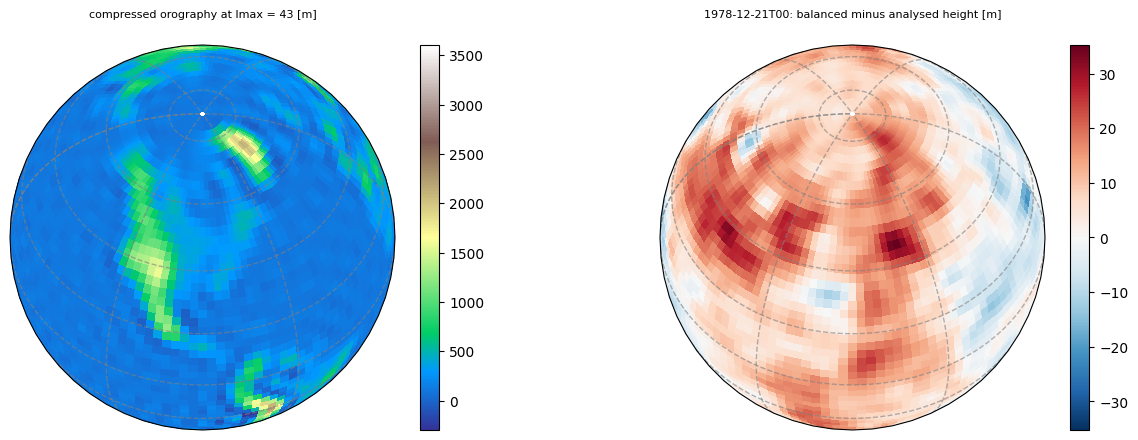

In [ ]:
fig = plt.figure(figsize=(13, 5))
panels = fig.subfigures(1, 2)
plot_sphere(
    orography, fig=panels[0], grid=simulators["era5"].grid,
    projection="orthographic", central_latitude=view_latitude, central_longitude=view_longitude,
    cmap="terrain", colorbar=True, gridlines=True,
    title="compressed orography at lmax = 43 [m]",
)
limit = balance_change.abs().max().item()
plot_sphere(
    balance_change, fig=panels[1], grid=simulators["era5"].grid,
    projection="orthographic", central_latitude=view_latitude, central_longitude=view_longitude,
    cmap="RdBu_r", vmin=-limit, vmax=limit, colorbar=True, gridlines=True,
    title="1978-12-21T00: balanced minus analysed height [m]",
)
fig.savefig("figures/benchmark_era5.png", dpi=110, bbox_inches="tight")
plt.show()